# NAME: PRABHKIRAT SINGH MARWAH 
# SECTION: B
# BATCH: B4
# ROLL NO: 47
# ML LAB 8

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("ml_8.csv")

In [3]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [5]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,
                             confusion_matrix,ConfusionMatrixDisplay)


In [8]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
X = df[[
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]]

In [11]:
y=df["Machine failure"]

In [12]:
print("Input Shape:",X.shape)
print("Output Shape:",y.shape)

Input Shape: (10000, 6)
Output Shape: (10000,)


In [13]:
categorical_features=["Type"]
numerical_features=[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]


In [14]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Train Shape:",X_train.shape[0])
print("Test Shape:",X_test.shape[0])

Train Shape: 8000
Test Shape: 2000


In [15]:
from sklearn.preprocessing import OneHotEncoder
preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numerical_features),
        ("cat",OneHotEncoder(handle_unknown="ignore"),categorical_features)
    ]
)


In [16]:
# 1. Correct the feature list definitions
categorical_features = ["Type"]
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# 2. Rebuild the preprocessor with the correct features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# 3. Rebuild and fit the pipeline
linear_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="linear"))
    ]
)

linear_svm.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).B

In [17]:
y_pred_linear=linear_svm.predict(X_test)

In [18]:
accuracy_linear=accuracy_score(y_test,y_pred_linear)
precision_linear=precision_score(y_test,y_pred_linear,zero_division=0)
recall_linear=recall_score(y_test,y_pred_linear,zero_division=0)
f1_linear=f1_score(y_test,y_pred_linear,zero_division=0)
print("Accuracy:",accuracy_linear)
print("Precision:",precision_linear)
print("Recall:",recall_linear)
print("F1 Score:",f1_linear)

Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [19]:
print(classification_report(y_test,y_pred_linear,target_names=["No Failure","Failure"],zero_division=0))


              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



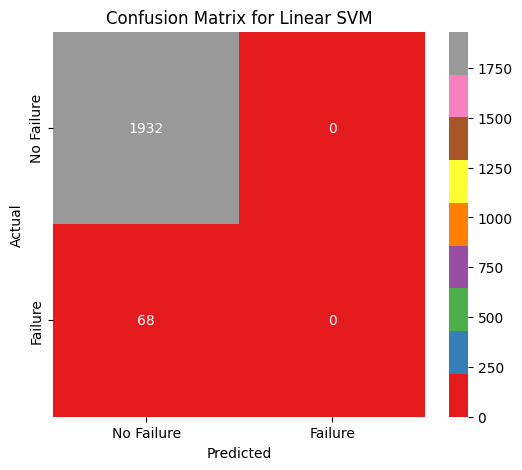

In [20]:
cm_linear=confusion_matrix(y_test,y_pred_linear)
plt.figure(figsize=(6,5))
sns.heatmap(cm_linear,annot=True,fmt="d",cmap="Set1",xticklabels=["No Failure","Failure"],yticklabels=["No Failure","Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Linear SVM")
plt.show()

In [21]:
rbf_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="rbf"))
    ]
)
rbf_svm.fit(X_train, y_train)
y_pred_rbf = rbf_svm.predict(X_test)
accuracy_rbf=accuracy_score(y_test,y_pred_rbf)
precision_rbf=precision_score(y_test,y_pred_rbf,zero_division=0)
recall_rbf=recall_score(y_test,y_pred_rbf,zero_division=0)
f1_rbf=f1_score(y_test,y_pred_rbf,zero_division=0)


In [22]:
print(classification_report(y_test,y_pred_rbf,target_names=["No Failure","Failure"],zero_division=0))

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



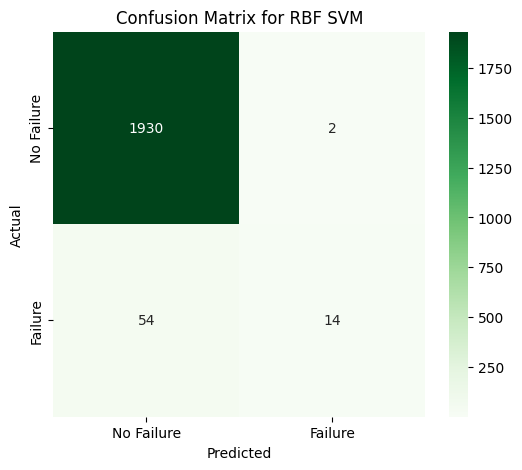

In [23]:
cm_rbf=confusion_matrix(y_test,y_pred_rbf)
plt.figure(figsize=(6,5))
sns.heatmap(cm_rbf,annot=True,fmt="d",cmap="Greens",xticklabels=["No Failure","Failure"],yticklabels=["No Failure","Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for RBF SVM")
plt.show()

--- Polynomial SVM Performance ---
Accuracy: 0.9745
Precision: 0.8695652173913043
Recall: 0.29411764705882354
F1 Score: 0.43956043956043955



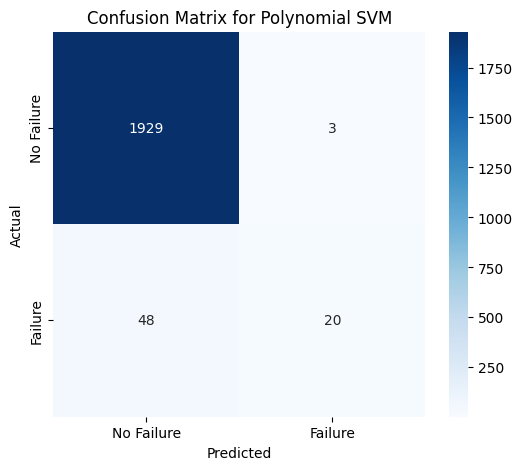

--- Sigmoid SVM Performance ---
Accuracy: 0.945
Precision: 0.15
Recall: 0.1323529411764706
F1 Score: 0.140625


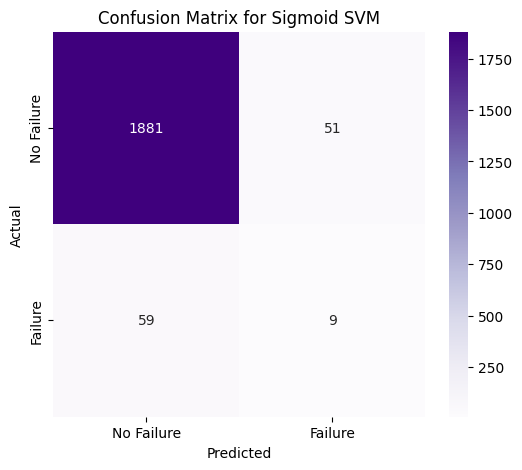

In [24]:
# ---- Polynomial SVM ----
poly_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="poly", degree=3))
    ]
)
poly_svm.fit(X_train, y_train)
y_pred_poly = poly_svm.predict(X_test)

accuracy_poly = accuracy_score(y_test, y_pred_poly)
precision_poly = precision_score(y_test, y_pred_poly, zero_division=0)
recall_poly = recall_score(y_test, y_pred_poly, zero_division=0)
f1_poly = f1_score(y_test, y_pred_poly, zero_division=0)

print("--- Polynomial SVM Performance ---")
print("Accuracy:", accuracy_poly)
print("Precision:", precision_poly)
print("Recall:", recall_poly)
print("F1 Score:", f1_poly)
print()
cm_poly=confusion_matrix(y_test,y_pred_poly)
plt.figure(figsize=(6,5))
sns.heatmap(cm_poly,annot=True,fmt="d",cmap="Blues",xticklabels=["No Failure","Failure"],yticklabels=["No Failure","Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Polynomial SVM")
plt.show()

# ---- Sigmoid SVM ----
sigmoid_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="sigmoid"))
    ]
)
sigmoid_svm.fit(X_train, y_train)
y_pred_sigmoid = sigmoid_svm.predict(X_test)

accuracy_sigmoid = accuracy_score(y_test, y_pred_sigmoid)
precision_sigmoid = precision_score(y_test, y_pred_sigmoid, zero_division=0)
recall_sigmoid = recall_score(y_test, y_pred_sigmoid, zero_division=0)
f1_sigmoid = f1_score(y_test, y_pred_sigmoid, zero_division=0)

print("--- Sigmoid SVM Performance ---")
print("Accuracy:", accuracy_sigmoid)
print("Precision:", precision_sigmoid)
print("Recall:", recall_sigmoid)
print("F1 Score:", f1_sigmoid)
cm_sigmoid=confusion_matrix(y_test,y_pred_sigmoid)
plt.figure(figsize=(6,5))
sns.heatmap(cm_sigmoid,annot=True,fmt="d",cmap="Purples",xticklabels=["No Failure","Failure"],yticklabels=["No Failure","Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Sigmoid SVM")
plt.show()

In [25]:
comparison = pd.DataFrame({
    "Kernel": ["Linear", "RBF", "Polynomial (Degree 3)", "Sigmoid"],
    "Accuracy": [accuracy_linear, accuracy_rbf, accuracy_poly, accuracy_sigmoid],
    "Precision": [precision_linear, precision_rbf, precision_poly, precision_sigmoid],
    "Recall": [recall_linear, recall_rbf, recall_poly, recall_sigmoid],
    "F1 Score": [f1_linear, f1_rbf, f1_poly, f1_sigmoid]
})

comparison

,Kernel,Accuracy,Precision,Recall,F1 Score
0,Linear,0.9660,0.000000,0.000000,0.000000
1,RBF,0.9720,0.875000,0.205882,0.333333
2,Polynomial (Degree 3),0.9745,0.869565,0.294118,0.439560
3,Sigmoid,0.9450,0.150000,0.132353,0.140625


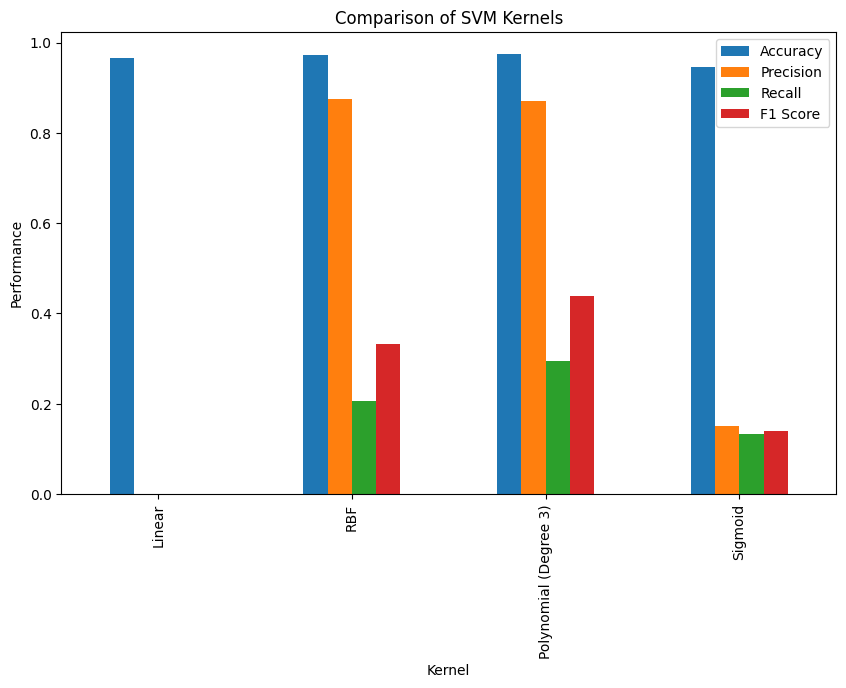

In [26]:
comparision_plot=comparison.plot(x="Kernel",y=["Accuracy","Precision","Recall","F1 Score"],kind="bar",figsize=(10,6))
comparision_plot.set_xlabel("Kernel")
comparision_plot.set_ylabel("Performance")
comparision_plot.set_title("Comparison of SVM Kernels")
plt.show()

In [27]:
from sklearn.pipeline import Pipeline
pipeline=Pipeline(steps=[("preprocessor",preprocessor),("classifier",SVC())])

In [28]:
param_grid = [
    {"classifier__kernel": ["linear"], "classifier__C": [0.1, 1, 10, 100]},
    {"classifier__kernel": ["rbf", "sigmoid"], "classifier__C": [0.1, 1, 10, 100], "classifier__gamma": ["scale", 0.01, 0.1, 1]}
]

In [29]:
from sklearn.model_selection import RandomizedSearchCV

# This will randomly pick just 10 combinations instead of all 60
grid_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    n_jobs=-1,
    scoring="f1",
    verbose=1,
    random_state=42
)

In [30]:
grid_search.fit(X_train, y_train)
print("Best Parameters Found:", grid_search.best_params_)
print("Best Cross-Validation F1-Score:", grid_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters Found: {'classifier__kernel': 'rbf', 'classifier__gamma': 1, 'classifier__C': 10}
Best Cross-Validation F1-Score: 0.5340961622051239


In [31]:
y_pred_tuned = grid_search.predict(X_test)

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned, zero_division=0)
recall_tuned = recall_score(y_test, y_pred_tuned, zero_division=0)
f1_tuned = f1_score(y_test, y_pred_tuned, zero_division=0)

print("--- Best Tuned SVM Performance ---")
print("Accuracy:", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall:", recall_tuned)
print("F1 Score:", f1_tuned)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, target_names=["No Failure", "Failure"], zero_division=0))

--- Best Tuned SVM Performance ---
Accuracy: 0.977
Precision: 0.7115384615384616
Recall: 0.5441176470588235
F1 Score: 0.6166666666666667

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.98      0.99      0.99      1932
     Failure       0.71      0.54      0.62        68

    accuracy                           0.98      2000
   macro avg       0.85      0.77      0.80      2000
weighted avg       0.97      0.98      0.98      2000



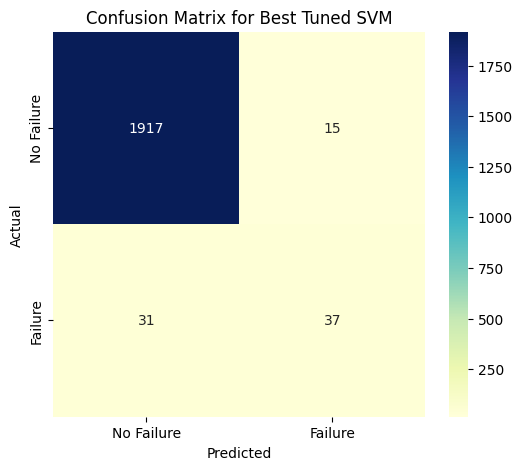

In [32]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(6,5))
sns.heatmap(cm_tuned, annot=True, fmt="d", cmap="YlGnBu", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Best Tuned SVM")
plt.show()

In [33]:
final_comparison = pd.DataFrame({
    "Kernel/Model": ["Linear", "RBF", "Polynomial (Degree 3)", "Sigmoid", "Best Tuned SVM"],
    "Accuracy": [accuracy_linear, accuracy_rbf, accuracy_poly, accuracy_sigmoid, accuracy_tuned],
    "Precision": [precision_linear, precision_rbf, precision_poly, precision_sigmoid, precision_tuned],
    "Recall": [recall_linear, recall_rbf, recall_poly, recall_sigmoid, recall_tuned],
    "F1 Score": [f1_linear, f1_rbf, f1_poly, f1_sigmoid, f1_tuned]
})

display(final_comparison)

,Kernel/Model,Accuracy,Precision,Recall,F1 Score
0,Linear,0.9660,0.000000,0.000000,0.000000
1,RBF,0.9720,0.875000,0.205882,0.333333
2,Polynomial (Degree 3),0.9745,0.869565,0.294118,0.439560
3,Sigmoid,0.9450,0.150000,0.132353,0.140625
4,Best Tuned SVM,0.9770,0.711538,0.544118,0.616667


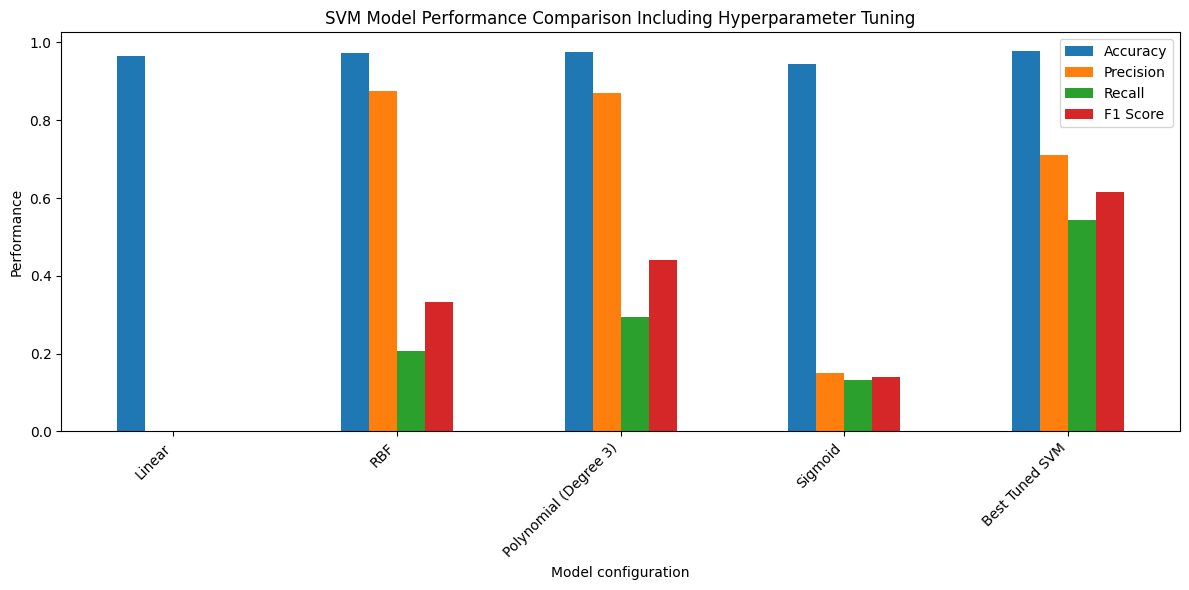

In [34]:
final_plot = final_comparison.plot(x="Kernel/Model", y=["Accuracy", "Precision", "Recall", "F1 Score"], kind="bar", figsize=(12,6))
final_plot.set_xlabel("Model configuration")
final_plot.set_ylabel("Performance")
final_plot.set_title("SVM Model Performance Comparison Including Hyperparameter Tuning")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()